<a href="https://colab.research.google.com/github/lakshkurhadkar-dot/MDM-3/blob/main/mdm_3_project_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    "AI_SocialMedia_Student_Dataset.csv"
)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Saving AI_SocialMedia_Student_Dataset.csv to AI_SocialMedia_Student_Dataset (1).csv
Dataset Shape: (16000, 10)

First 5 Rows:


,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04



Column Names:
['Student_ID', 'Age', 'Gender', 'Education_Level', 'Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours', 'Sleep_Hours', 'Physical_Activity_Hours', 'Mental_Health_Score', 'Physical_Health_Score']

Missing Values:
Student_ID                   0
Age                          0
Gender                       0
Education_Level              0
Daily_Social_Media_Hours     0
Daily_AI_Tool_Usage_Hours    0
Sleep_Hours                  0
Physical_Activity_Hours      0
Mental_Health_Score          0
Physical_Health_Score        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,Age,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
count,16000.00000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,19.03875,4.541791,2.590624,6.545371,1.248359,72.493193,88.020465
std,3.76527,2.403044,1.679376,1.270515,1.038632,9.244818,9.691037
min,13.00000,0.000000,0.000000,2.000000,0.000000,32.560000,48.030000
25%,16.00000,2.840000,1.310000,5.680000,0.310000,66.760000,81.517500
50%,19.00000,4.500000,2.520000,6.540000,1.130000,73.750000,89.455000
75%,22.00000,6.180000,3.750000,7.410000,1.960000,79.550000,97.170000
max,25.00000,14.000000,9.500000,11.150000,5.000000,91.760000,99.980000


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded.keys())))

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Saving AI_SocialMedia_Student_Dataset.csv to AI_SocialMedia_Student_Dataset (2).csv
Dataset shape: (16000, 10)
  Student_ID  Age      Gender Education_Level  Daily_Social_Media_Hours  \
0  STU_00001   19        Male         College                      5.32   
1  STU_00002   16  Non-binary     High School                      5.21   
2  STU_00003   25        Male      University                      3.61   
3  STU_00004   23        Male      University                      2.93   
4  STU_00005   20  Non-binary         College                      6.52   

   Daily_AI_Tool_Usage_Hours  Sleep_Hours  Physical_Activity_Hours  \
0                       1.21         7.30                     1.41   
1                       3.89         7.81                     2.48   
2                       2.65         6.34                     0.06   
3                       1.43         6.12                     1.37   
4                       1.64         5.23                     1.14   

   Mental_Health_

In [6]:
df = df.drop_duplicates().copy()

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(
            df[col].mode().iloc[0]
            if not df[col].mode().empty else "Unknown"
        )

print("Missing values:")
print(df.isnull().sum())
print("Dataset shape after cleaning:", df.shape)
print(df.describe())

Missing values:
Student_ID                   0
Age                          0
Gender                       0
Education_Level              0
Daily_Social_Media_Hours     0
Daily_AI_Tool_Usage_Hours    0
Sleep_Hours                  0
Physical_Activity_Hours      0
Mental_Health_Score          0
Physical_Health_Score        0
dtype: int64
Dataset shape after cleaning: (16000, 10)
               Age  Daily_Social_Media_Hours  Daily_AI_Tool_Usage_Hours  \
count  16000.00000              16000.000000               16000.000000   
mean      19.03875                  4.541791                   2.590624   
std        3.76527                  2.403044                   1.679376   
min       13.00000                  0.000000                   0.000000   
25%       16.00000                  2.840000                   1.310000   
50%       19.00000                  4.500000                   2.520000   
75%       22.00000                  6.180000                   3.750000   
max       25.00000 

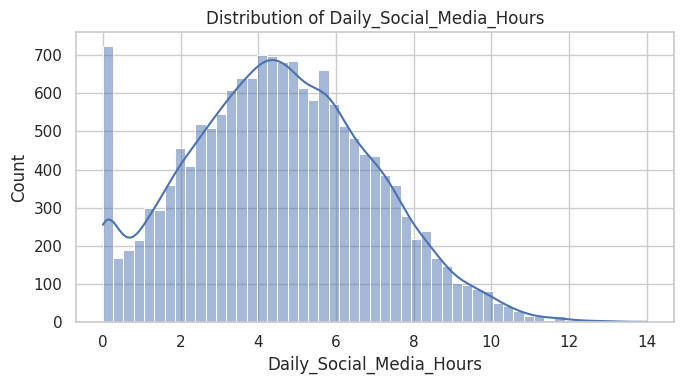

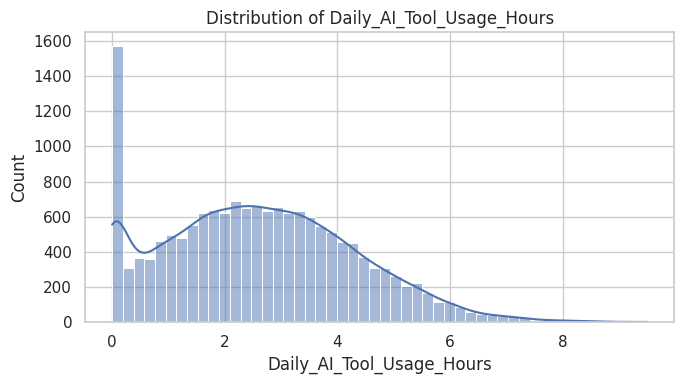

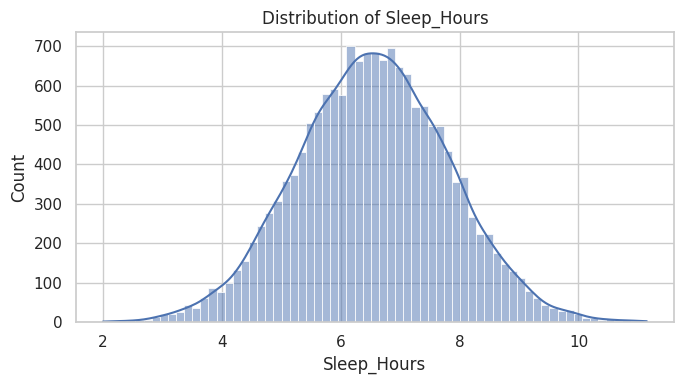

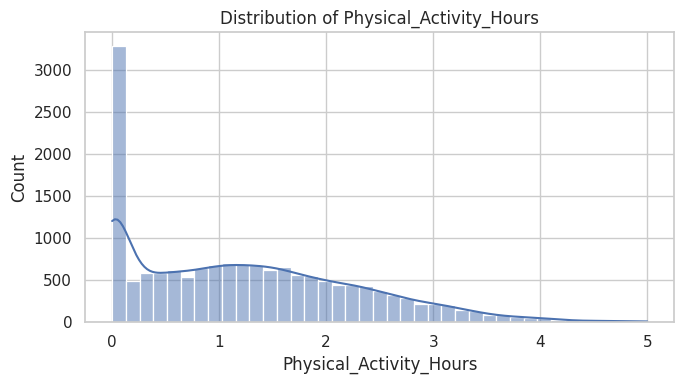

In [7]:
columns = [
    "Daily_Social_Media_Hours",
    "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours"
]

for col in columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

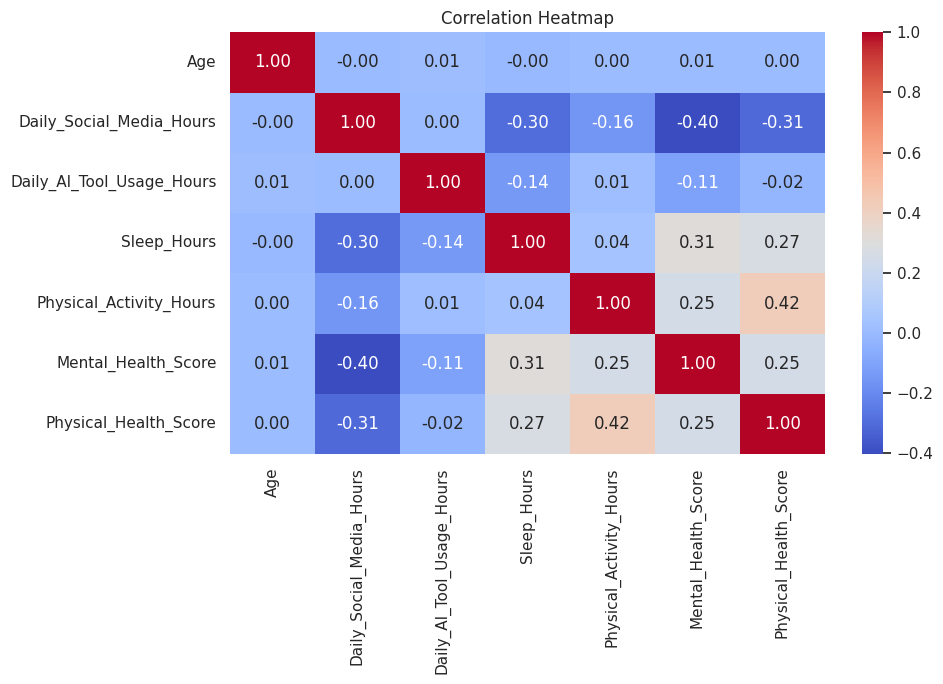

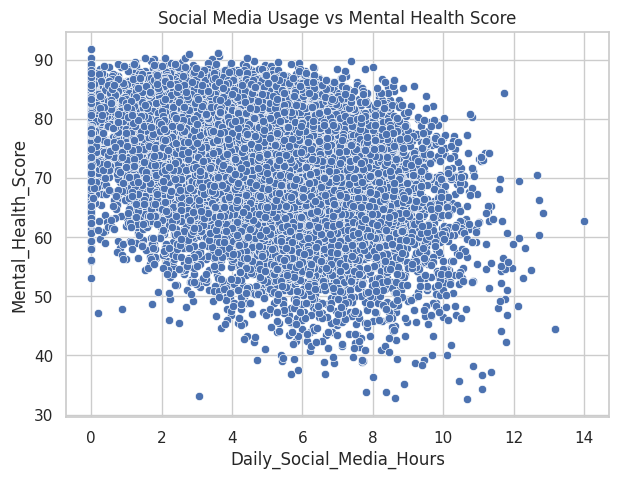

In [8]:
health_cols = [
    "Age",
    "Daily_Social_Media_Hours",
    "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours",
    "Mental_Health_Score",
    "Physical_Health_Score"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[health_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Daily_Social_Media_Hours",
    y="Mental_Health_Score"
)
plt.title("Social Media Usage vs Mental Health Score")
plt.show()

In [9]:
cluster_features = [
    "Daily_Social_Media_Hours",
    "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours",
    "Mental_Health_Score",
    "Physical_Health_Score"
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_features])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Student_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Student_Cluster"].value_counts().sort_index())

print("\nCluster summary:")
print(df.groupby("Student_Cluster")[cluster_features].mean().round(2))

Cluster counts:
Student_Cluster
0    5459
1    5669
2    4872
Name: count, dtype: int64

Cluster summary:
                 Daily_Social_Media_Hours  Daily_AI_Tool_Usage_Hours  \
Student_Cluster                                                        
0                                    3.46                       1.95   
1                                    6.30                       2.95   
2                                    3.71                       2.88   

                 Sleep_Hours  Physical_Activity_Hours  Mental_Health_Score  \
Student_Cluster                                                              
0                       7.35                     0.74                76.43   
1                       5.71                     0.75                65.28   
2                       6.61                     2.40                76.48   

                 Physical_Health_Score  
Student_Cluster                         
0                                89.23  
1                  

In [10]:
cluster_features = [
    "Daily_Social_Media_Hours",
    "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours",
    "Mental_Health_Score",
    "Physical_Health_Score"
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_features])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Student_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Student_Cluster"].value_counts().sort_index())

print("\nCluster summary:")
print(df.groupby("Student_Cluster")[cluster_features].mean().round(2))

Cluster counts:
Student_Cluster
0    5459
1    5669
2    4872
Name: count, dtype: int64

Cluster summary:
                 Daily_Social_Media_Hours  Daily_AI_Tool_Usage_Hours  \
Student_Cluster                                                        
0                                    3.46                       1.95   
1                                    6.30                       2.95   
2                                    3.71                       2.88   

                 Sleep_Hours  Physical_Activity_Hours  Mental_Health_Score  \
Student_Cluster                                                              
0                       7.35                     0.74                76.43   
1                       5.71                     0.75                65.28   
2                       6.61                     2.40                76.48   

                 Physical_Health_Score  
Student_Cluster                         
0                                89.23  
1                  

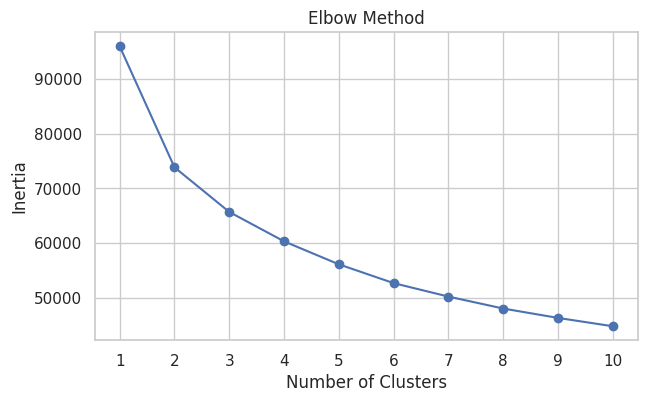

In [11]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [19]:
features = [
    "Age",
    "Daily_Social_Media_Hours",
    "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours",
    "Physical_Health_Score"
]

X = df[features]
y = df["Mental_Health_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Rename 'model' to 'rf_model' to avoid collisions with KMeans variables
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print("Model trained successfully as 'rf_model'!")

Model trained successfully as 'rf_model'!


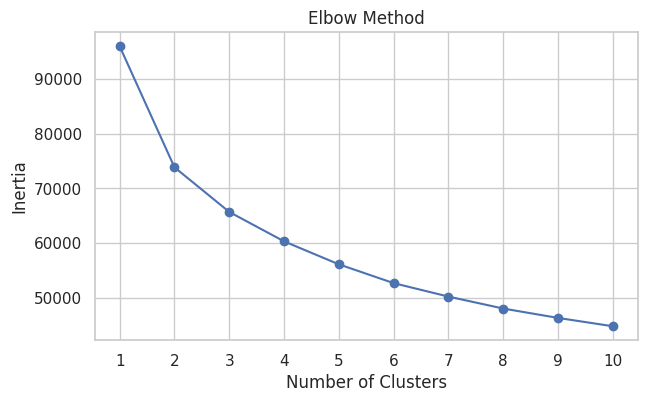

In [13]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [18]:
# Ensure you use 'rf_model' here instead of 'model' to avoid conflicts with 'KMeans' objects
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R-squared:", round(r2, 3))

# Using 'rf_model' to safely query the random forest feature importances
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values()

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Mental Health Score")
plt.ylabel("Predicted Mental Health Score")
plt.title("Actual vs Predicted")
plt.show()

MAE: 6.122
RMSE: 7.885
R-squared: 0.263


NameError: name 'rf_model' is not defined

In [17]:
print("PROJECT SUMMARY")
print("----------------")
print("Total students:", len(df))
print("Average social media hours:",
      round(df["Daily_Social_Media_Hours"].mean(), 2))
print("Average sleep hours:",
      round(df["Sleep_Hours"].mean(), 2))
print("Average mental health score:",
      round(df["Mental_Health_Score"].mean(), 2))
print("Model MAE:", round(mae, 3))
print("Model RMSE:", round(rmse, 3))
print("Model R2:", round(r2, 3))

df.to_csv("MDM3_Final_Results.csv", index=False)

predictions = pd.DataFrame({
    "Actual_Score": y_test.values,
    "Predicted_Score": y_pred
})
predictions.to_csv("MDM3_Predictions.csv", index=False)

files.download("MDM3_Final_Results.csv")
files.download("MDM3_Predictions.csv")

PROJECT SUMMARY
----------------
Total students: 16000
Average social media hours: 4.54
Average sleep hours: 6.55
Average mental health score: 72.49
Model MAE: 6.122
Model RMSE: 7.885
Model R2: 0.263


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>